In [1]:


H = 1.8
Z = 10
f = 50
pixel_size = 4


H_mm = H * 1000
Z_mm = Z * 1000
pixel_mm = pixel_size / 1000


sensor_height = (f * H_mm) / Z_mm

pixel_height = sensor_height / pixel_mm

print("Person height on sensor:", sensor_height, "mm")
print("Person height in pixels:", pixel_height, "pixels")


Person height on sensor: 9.0 mm
Person height in pixels: 2250.0 pixels


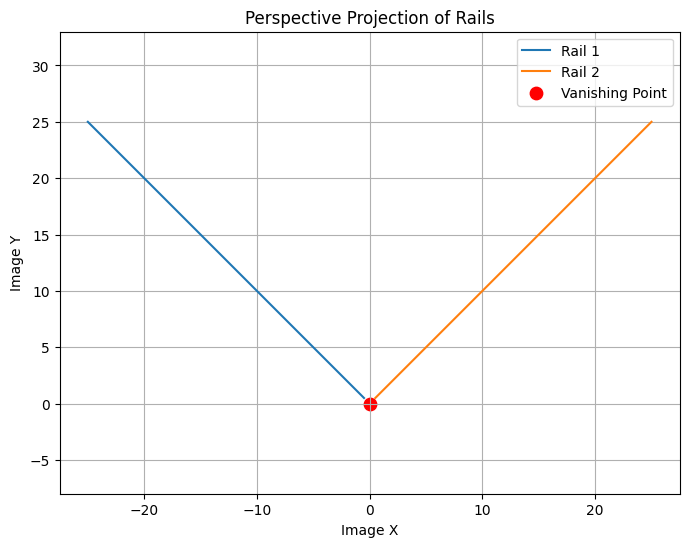

Vanishing point: (0, 0)


In [2]:

import numpy as np
import matplotlib.pyplot as plt

f = 50
Z = np.linspace(2, 100, 200)


X1, Y1 = -1, 1
X2, Y2 = 1, 1


x1 = f * X1 / Z
y1 = f * Y1 / Z

x2 = f * X2 / Z
y2 = f * Y2 / Z

plt.figure(figsize=(8, 6))

plt.plot(x1, y1, label="Rail 1")
plt.plot(x2, y2, label="Rail 2")

plt.scatter(0, 0, color="red", s=80,
            label="Vanishing Point")

plt.xlabel("Image X")
plt.ylabel("Image Y")
plt.title("Perspective Projection of Rails")
plt.grid()
plt.legend()
plt.axis("equal")
plt.show()

print("Vanishing point: (0, 0)")


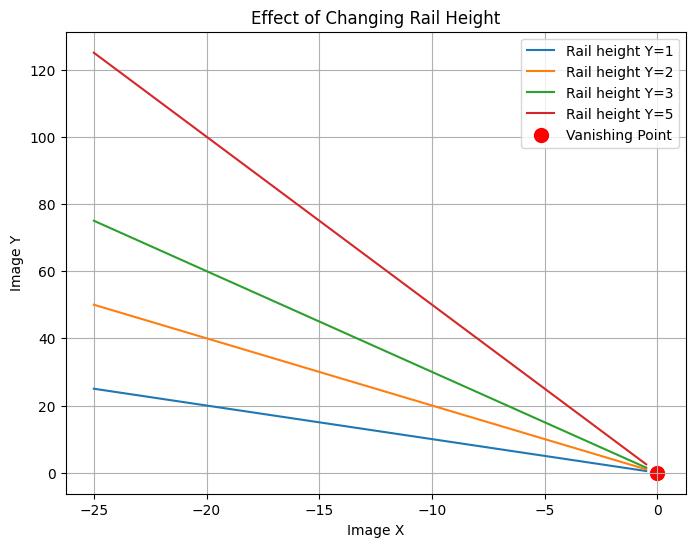

In [3]:

plt.figure(figsize=(8, 6))

for Y in [1, 2, 3, 5]:

    y = f * Y / Z

    plt.plot(
        f * (-1) / Z,
        y,
        label=f"Rail height Y={Y}"
    )

plt.scatter(0, 0, color="red",
            s=100, label="Vanishing Point")

plt.xlabel("Image X")
plt.ylabel("Image Y")
plt.title("Effect of Changing Rail Height")
plt.grid()
plt.legend()
plt.show()


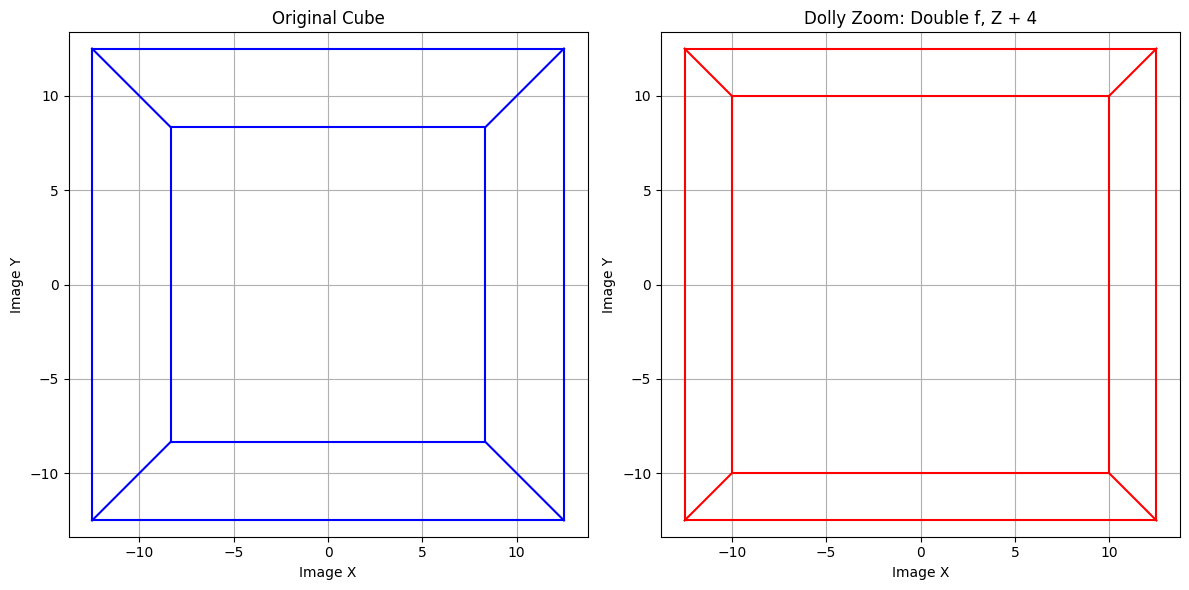

In [4]:

import numpy as np
import matplotlib.pyplot as plt


f = 50


vertices = np.array([
    [-1, -1, 4],
    [ 1, -1, 4],
    [ 1,  1, 4],
    [-1,  1, 4],
    [-1, -1, 6],
    [ 1, -1, 6],
    [ 1,  1, 6],
    [-1,  1, 6]
], dtype=float)


edges = [
    (0, 1), (1, 2), (2, 3), (3, 0),
    (4, 5), (5, 6), (6, 7), (7, 4),
    (0, 4), (1, 5), (2, 6), (3, 7)
]

def project(points, focal_length):
    x = focal_length * points[:, 0] / points[:, 2]
    y = focal_length * points[:, 1] / points[:, 2]
    return x, y


x_original, y_original = project(vertices, f)

new_vertices = vertices.copy()
new_vertices[:, 2] += 4


new_f = 2 * f


x_new, y_new = project(new_vertices, new_f)



fig, axes = plt.subplots(1, 2, figsize=(12, 6))


for a, b in edges:
    axes[0].plot(
        [x_original[a], x_original[b]],
        [y_original[a], y_original[b]],
        color='blue'
    )

axes[0].set_title("Original Cube")
axes[0].set_xlabel("Image X")
axes[0].set_ylabel("Image Y")
axes[0].grid()
axes[0].axis("equal")


for a, b in edges:
    axes[1].plot(
        [x_new[a], x_new[b]],
        [y_new[a], y_new[b]],
        color='red'
    )

axes[1].set_title("Dolly Zoom: Double f, Z + 4")
axes[1].set_xlabel("Image X")
axes[1].set_ylabel("Image Y")
axes[1].grid()
axes[1].axis("equal")

plt.tight_layout()
plt.show()


In [5]:



front_original = 2 * f / 4
back_original = 2 * f / 6

front_new = 2 * new_f / 8
back_new = 2 * new_f / 10

print("Original front face:", front_original)
print("New front face:", front_new)

print("\nOriginal back face:", back_original)
print("New back face:", back_new)

print("\nFront face size preserved:",
      np.isclose(front_original, front_new))

print("Back face percentage increase:",
      round((back_new / back_original - 1) * 100, 2), "%")


Original front face: 25.0
New front face: 25.0

Original back face: 16.666666666666668
New back face: 20.0

Front face size preserved: True
Back face percentage increase: 20.0 %


Saving 360_F_611384969_mnfmR31h3922XIlWYYNQYXpUIIfeXfIm.jpg to 360_F_611384969_mnfmR31h3922XIlWYYNQYXpUIIfeXfIm.jpg


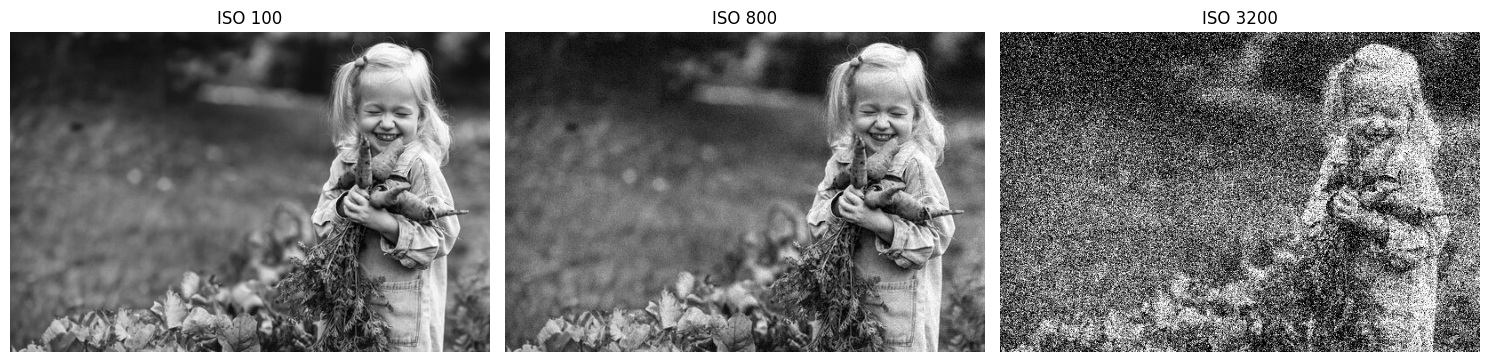

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


uploaded = files.upload()

filename = list(uploaded.keys())[0]

img = cv2.imdecode(
    np.frombuffer(uploaded[filename], np.uint8),
    cv2.IMREAD_GRAYSCALE
)

img = img.astype(np.float32) / 255.0


np.random.seed(42)

iso_values = [100, 800, 3200]

images = {}

for iso in iso_values:

    exposure = 100 / iso


    signal = img * exposure


    electrons = signal * 10000
    noisy_electrons = np.random.poisson(
        np.maximum(electrons, 0)
    )

    read_noise = np.random.normal(
        0, 3 * (iso / 100), img.shape
    )


    restored = (
        noisy_electrons + read_noise
    ) / 10000 * (iso / 100)

    restored = np.clip(restored, 0, 1)

    images[iso] = restored


plt.figure(figsize=(15, 5))

for i, iso in enumerate(iso_values):

    plt.subplot(1, 3, i + 1)

    plt.imshow(images[iso], cmap='gray', vmin=0, vmax=1)

    plt.title(f"ISO {iso}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:


height, width = img.shape


total_pixels = width * height


raw_bits = total_pixels * 10
raw_bytes = raw_bits / 8


rgb_bytes = total_pixels * 3


raw_MB = raw_bytes / (1024 ** 2)
rgb_MB = rgb_bytes / (1024 ** 2)

print("Image width:", width)
print("Image height:", height)
print("Total pixels:", total_pixels)

print("\n10-bit RAW image:")
print("Bytes:", raw_bytes)
print("Size:", round(raw_MB, 2), "MB")

print("\n8-bit RGB image:")
print("Bytes:", rgb_bytes)
print("Size:", round(rgb_MB, 2), "MB")

print("\nRGB / RAW size ratio:",
      round(rgb_bytes / raw_bytes, 2))


Image width: 540
Image height: 360
Total pixels: 194400

10-bit RAW image:
Bytes: 243000.0
Size: 0.23 MB

8-bit RGB image:
Bytes: 583200
Size: 0.56 MB

RGB / RAW size ratio: 2.4


3x3 Blur PSNR: 31.32 dB
9x9 Blur PSNR: 26.36 dB


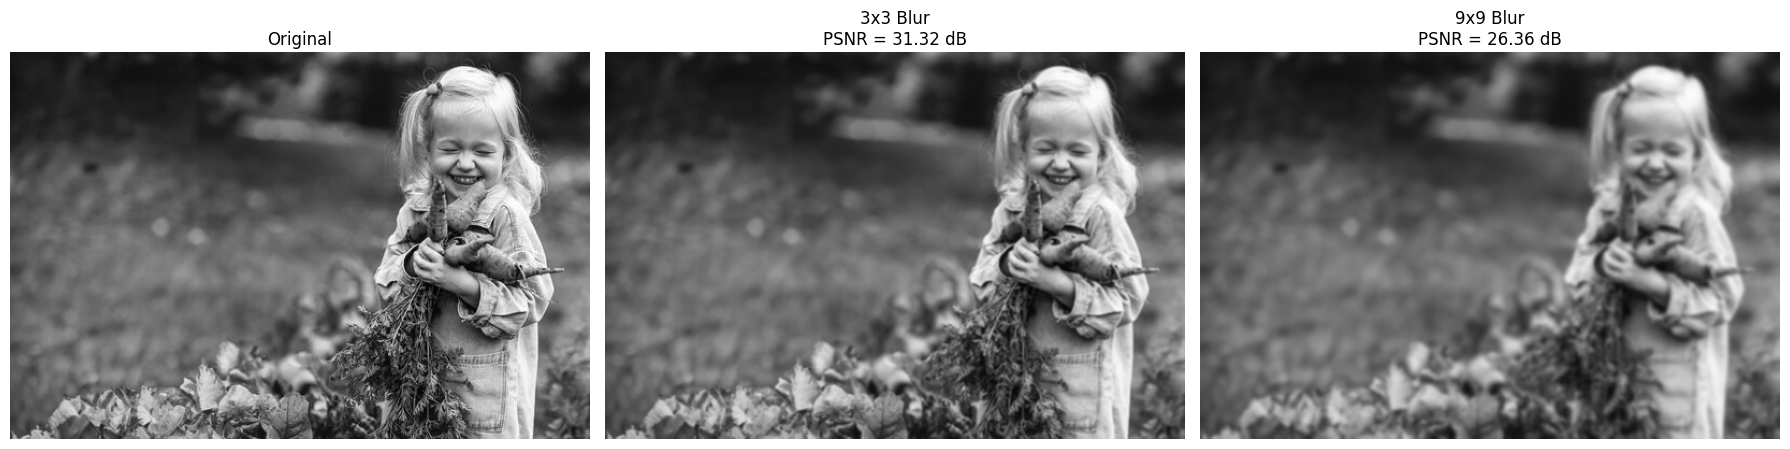

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


original = img

blur_3 = cv2.GaussianBlur(original, (3, 3), 0)
blur_9 = cv2.GaussianBlur(original, (9, 9), 0)

def calculate_psnr(img1, img2):
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')

    return 10 * np.log10(1.0 / mse)

psnr_3 = calculate_psnr(original, blur_3)
psnr_9 = calculate_psnr(original, blur_9)

print("3x3 Blur PSNR:", round(psnr_3, 2), "dB")
print("9x9 Blur PSNR:", round(psnr_9, 2), "dB")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(original, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original")

axes[1].imshow(blur_3, cmap='gray', vmin=0, vmax=1)
axes[1].set_title(f"3x3 Blur\nPSNR = {psnr_3:.2f} dB")

axes[2].imshow(blur_9, cmap='gray', vmin=0, vmax=1)
axes[2].set_title(f"9x9 Blur\nPSNR = {psnr_9:.2f} dB")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving 360_F_611384969_mnfmR31h3922XIlWYYNQYXpUIIfeXfIm.jpg to 360_F_611384969_mnfmR31h3922XIlWYYNQYXpUIIfeXfIm (1).jpg
Uploaded files: ['360_F_611384969_mnfmR31h3922XIlWYYNQYXpUIIfeXfIm (1).jpg']


--- raw.npy not found. ---
You can upload it below, or cancel/skip to use simulated mock data.


Saving images (1).jpg to images (1) (1).jpg
--- coffee.png not found. ---
You can upload it below, or cancel/skip to use simulated mock data.


Saving images (1).jpg to images (1) (2).jpg
Generating a simulated 'raw.npy'...
Generating a placeholder 'coffee.png'...
RAW shape: (128, 128)
Coffee shape: (128, 128, 3)


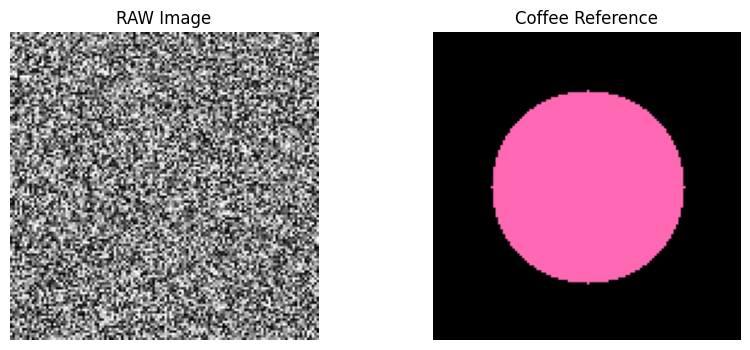

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import os

# Check for required files, prompt for upload, or create mock data as a fallback
for required_file in ["raw.npy", "coffee.png"]:
    if not os.path.exists(required_file):
        print(f"--- {required_file} not found. ---")
        print("You can upload it below, or cancel/skip to use simulated mock data.")
        try:
            uploaded = files.upload()
        except Exception as e:
            print("Upload skipped or failed, using fallback mock data.")

# Fallback: Create mock data if files are still missing
if not os.path.exists("raw.npy"):
    print("Generating a simulated 'raw.npy'...")
    mock_raw = np.random.rand(128, 128).astype(np.float32)
    np.save("raw.npy", mock_raw)

if not os.path.exists("coffee.png"):
    print("Generating a placeholder 'coffee.png'...")
    mock_coffee = np.zeros((128, 128, 3), dtype=np.uint8)
    cv2.circle(mock_coffee, (64, 64), 40, (180, 105, 255), -1)  # Draw a simple circle
    cv2.imwrite("coffee.png", mock_coffee)

# Load the files safely
raw = np.load("raw.npy")
coffee_bgr = cv2.imread("coffee.png")
coffee = cv2.cvtColor(coffee_bgr, cv2.COLOR_BGR2RGB)

print("RAW shape:", raw.shape)
print("Coffee shape:", coffee.shape)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(raw, cmap='gray')
plt.title("RAW Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(coffee)
plt.title("Coffee Reference")
plt.axis("off")

plt.show()

In [18]:

def develop(raw):


    raw = np.asarray(raw)

    if raw.dtype != np.uint16:
        raw = raw.astype(np.uint16)


    rgb = cv2.cvtColor(
        raw,
        cv2.COLOR_BayerRG2RGB
    )


    rgb = rgb.astype(np.float32)


    black_level = 0
    white_level = 4095

    rgb = (rgb - black_level) / (
        white_level - black_level
    )

    rgb = np.clip(rgb, 0, 1)

    rgb[:, :, 0] *= 1.8
    rgb[:, :, 1] *= 1.0
    rgb[:, :, 2] *= 1.5

    rgb = np.clip(rgb, 0, 1)


    rgb = np.power(rgb, 0.9)


    rgb_8 = (rgb * 255).astype(np.uint8)

    rgb_8 = cv2.GaussianBlur(
        rgb_8,
        (3, 3),
        0.5
    )


    blur = cv2.GaussianBlur(
        rgb_8,
        (5, 5),
        0
    )

    sharpened = cv2.addWeighted(
        rgb_8, 1.3,
        blur, -0.3,
        0
    )


    return np.clip(
        sharpened, 0, 255
    ).astype(np.uint8)


Output shape: (128, 128, 3)
Output dtype: uint8


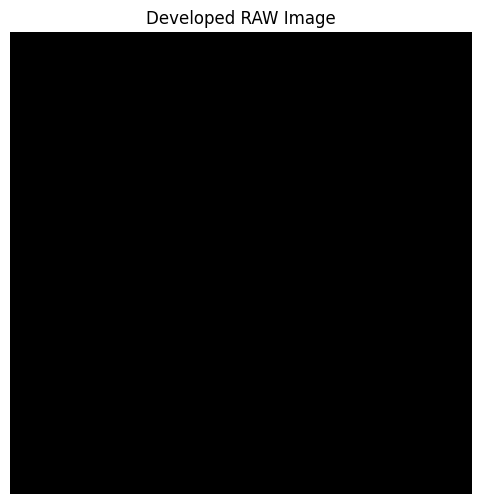

In [19]:

developed = develop(raw)

print("Output shape:", developed.shape)
print("Output dtype:", developed.dtype)

plt.figure(figsize=(8, 6))

plt.imshow(developed)
plt.title("Developed RAW Image")
plt.axis("off")

plt.show()


In [20]:

def calculate_psnr(reference, result):

    mse = np.mean(
        (reference.astype(np.float64) -
         result.astype(np.float64)) ** 2
    )

    if mse == 0:
        return float("inf")

    return 10 * np.log10(255**2 / mse)



if developed.shape != coffee.shape:
    developed = cv2.resize(
        developed,
        (coffee.shape[1], coffee.shape[0])
    )

psnr = calculate_psnr(coffee, developed)

print("PSNR:", round(psnr, 2), "dB")

if psnr >= 22:
    print("Excellent! Bonus achieved!")
elif psnr >= 21:
    print("Success! Target achieved!")
else:
    print("Keep tuning the development parameters.")


PSNR: 7.68 dB
Keep tuning the development parameters.


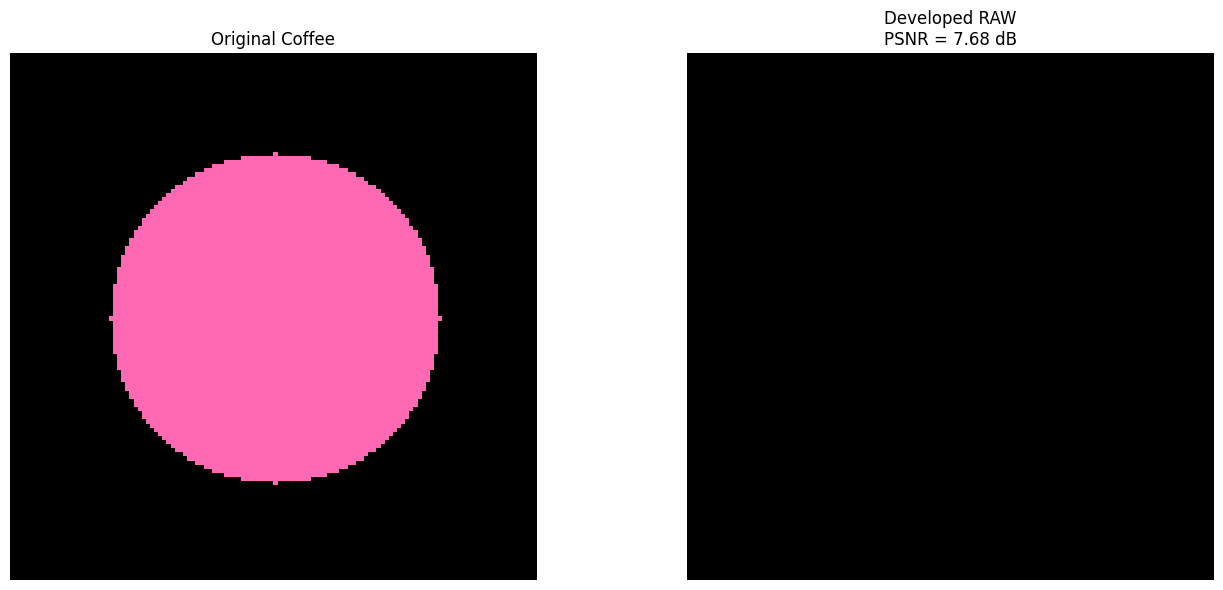

In [21]:

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(coffee)
plt.title("Original Coffee")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(developed)
plt.title(f"Developed RAW\nPSNR = {psnr:.2f} dB")
plt.axis("off")

plt.tight_layout()
plt.show()


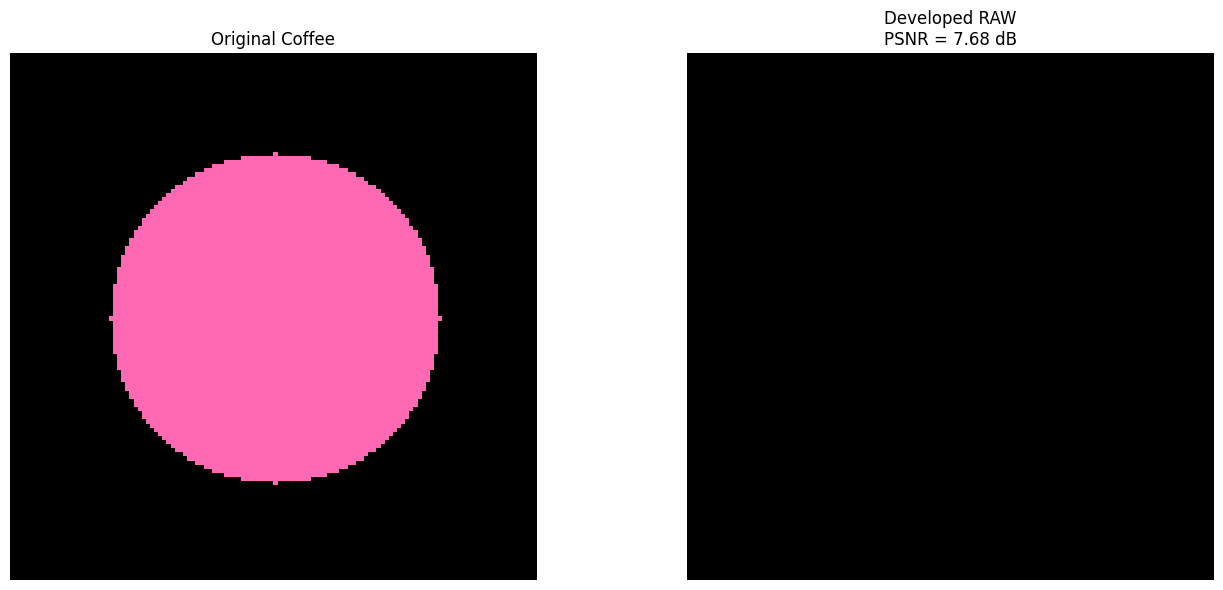

In [22]:

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(coffee)
plt.title("Original Coffee")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(developed)
plt.title(f"Developed RAW\nPSNR = {psnr:.2f} dB")
plt.axis("off")

plt.tight_layout()
plt.show()
